# 03 · Synthetic sales: how the data was made

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

This notebook only **prepares** the synthetic sales. The analysis is in `04_eda_with_synthetic_sales.ipynb`.

## 1. TL;DR

**What I did and found**

- The data has no copies sold, so for **70,361 books** with a list price I made four levels of yearly sales for 2019–2022.
- **A** (only verified purchases) gives **0.10 million** copies in 2022 and **B** (share of verified buyers) **4.0 million**: real minimums, but far too low.
- **D** (50 buyers per rating) gives **435.8 million**, about ten times too high.
- **C** (**5 buyers per rating**) gives **43.6 million**, close to the market check (**42.9 million**), so I use it as the **copies sold** in `04`.

## 2. Why synthetic sales, and four levels

The real data has no copies sold (`01_eda.ipynb`, 9.6). I create **synthetic sales** as a learning example,
starting from what **was measured**: the ratings of each book and the reviews of verified buyers. Instead of one number, I make four levels,
from a proven minimum upward:

| Level | Rule | Basis |
|---|---|---|
| **A. Proven minimum** | reviews marked `verified_purchase` | measured |
| **B. Basic minimum** | Amazon ratings × the book's share of verified reviews | measured share, applied to the ratings |
| **C. Middle** | ratings × buyers per rating with a median of **5**, checked against a rough size of the Kindle market | synthetic, **used as copies sold in `04`** |
| **D. High** | ratings × buyers per rating with a median of 50 | synthetic, the first version (archived in `notebooks/archive/03_first_synthetic/`) |

Only books with a real list price get sales. Books with price 0 are mostly in Kindle Unlimited.

## 3. Setup

| Constant | Value | Source |
|---|---|---|
| `KINDLE_EBOOKS_PER_YEAR` | 487 million | [WordsRated](https://wordsrated.com/amazon-publishing-statistics/): "Amazon sells over 487 million ebooks through Kindle every year". Low reliability: year and source not given. |
| `US_PUBLISHER_EBOOK_REVENUE` | 2.1 billion dollars (2024) | [AAP StatShot Annual 2024](https://publishers.org/news/aap-statshot-annual-report-publishing-revenues-totaled-32-5-billion-for-calendar-year-2024/), used only as a cross-check |
| `BUYERS_MEDIAN`, `BUYERS_P10`, `BUYERS_P90` | 50, 20, 125 | level D, as in the first version |
| `BUYERS_C_MEDIAN` | 5 | level C: the same random numbers divided by 10, a round number close to the market check |
| `SMALL_SAMPLE` | 5 reviews | books with fewer reviews get their niche's verified share |
| `SEED` | 42 | the same data every time |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
RAW_FILE = PROJECT / "data" / "raw" / "meta_Kindle_Store.jsonl"
REVIEWS_FILE = PROJECT / "data" / "raw" / "Kindle_Store_reviews.jsonl"
CLEAN, PROCESSED = PROJECT / "data" / "clean", PROJECT / "data" / "processed"

KINDLE_EBOOKS_PER_YEAR = 487_000_000
US_PUBLISHER_EBOOK_REVENUE = 2.1e9
BUYERS_MEDIAN, BUYERS_P10, BUYERS_P90 = 50, 20, 125
BUYERS_C_MEDIAN = 5
SMALL_SAMPLE = 5
LARGE_PUBLISHER_MIN = 500
SEED = 42
YEARS = [2019, 2020, 2021, 2022]
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#c3c2b7", "#3a9a5b"
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 45)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
print("Ready")

Ready


## 4. Books, publishing route and file size

I take the clean books with a list price, and from the original file the publisher's size and the file size. A book is **self-published** by the
rule of `01_eda.ipynb`, 7.6; otherwise its publisher is **large** with at least 500 books in the catalog, and **small** with fewer.

In [2]:
books = pd.read_parquet(PROCESSED / "kindle_books_model.parquet")
books = books.merge(pd.read_parquet(CLEAN / "kindle_sample_2019_2022.parquet", columns=["parent_asin", "publisher", "published"]), on="parent_asin")
books["published"] = pd.to_datetime(books["published"])
paid = books[books["price"] > 0].copy()

raw = (pl.scan_ndjson(RAW_FILE, infer_schema_length=None)
       .select("parent_asin", pl.col("details").struct.field("Publisher").alias("publisher"),
               pl.col("details").struct.field("File size").alias("file_size"))
       .collect(engine="streaming")
       .with_columns(pl.col("publisher").str.replace_all(r"\s*\([^()]*\d{4}\)\s*$", "").str.split(";").list.first()
                     .str.strip_chars().replace("", None).alias("publisher_clean")))
publisher_size = raw.drop_nulls("publisher_clean").group_by("publisher_clean").len().to_pandas().set_index("publisher_clean")["len"]
file_mb = (raw.select("parent_asin", pl.col("file_size").str.replace_all(",", "").str.extract(r"([\d.]+)\s*KB", 1)
                      .cast(pl.Float64, strict=False).alias("kb")).to_pandas().set_index("parent_asin")["kb"] / 1024)

paid["publisher_clean"] = (paid["publisher"].fillna("").str.replace(r"\s*\([^()]*\d{4}\)\s*$", "", regex=True)
                           .str.split(";").str[0].str.strip().replace("", np.nan))
paid["publisher_books"] = paid["publisher_clean"].map(publisher_size).fillna(0).astype(int)
paid["route"] = np.select([paid["self_published"] == 1, paid["publisher_books"] >= LARGE_PUBLISHER_MIN],
                          ["self-published", "large publisher"], "small publisher")
paid["file_mb"] = paid["parent_asin"].map(file_mb)
paid["file_mb"] = paid["file_mb"].fillna(paid["file_mb"].median())
print(f"Books with a list price: {len(paid):,}")
paid["route"].value_counts().to_frame("books")

Books with a list price: 70,442


,books
route,
self-published,33842
small publisher,26651
large publisher,9949


- **70,442** books have a list price: **33,842** self-published, **26,651** with a small publisher and **9,949** with a large publisher.

## 5. Reviews and verified purchases

The reviews file has one row per review, with the field `verified_purchase` (True if Amazon confirmed that the reviewer bought the book). I read
three fields of the 15.8 GB file with Polars: the book, the year and `verified_purchase`. I also count the reviews of the **whole file** per year,
for the market check in section 7.

In [3]:
reviews = (pl.scan_ndjson(REVIEWS_FILE)
           .select("parent_asin", pl.from_epoch("timestamp", time_unit="ms").dt.year().alias("year"), "verified_purchase")
           .collect(engine="streaming"))
file_by_year = reviews.group_by("year").len().to_pandas().set_index("year")["len"].sort_index()
mine = reviews.filter(pl.col("parent_asin").is_in(paid["parent_asin"].to_list())).to_pandas()
del reviews
print(f"Reviews of my books: {len(mine):,} | verified: {mine['verified_purchase'].mean():.1%}")

per_book = mine.groupby("parent_asin").agg(reviews_all=("verified_purchase", "size"), verified_all=("verified_purchase", "sum"))
paid = paid.merge(per_book, left_on="parent_asin", right_index=True, how="left").fillna({"reviews_all": 0, "verified_all": 0})
print(f"Books without any review in the file (removed): {(paid['reviews_all'] == 0).sum():,}")
paid = paid[paid["reviews_all"] > 0].copy()
paid["verified_share_raw"] = paid["verified_all"] / paid["reviews_all"]
paid.groupby("route")[["reviews_all", "verified_all"]].sum().assign(verified_pct=lambda t: t["verified_all"] / t["reviews_all"] * 100).round(1)

Reviews of my books: 693,647 | verified: 56.1%


Books without any review in the file (removed): 81


,reviews_all,verified_all,verified_pct
route,,,
large publisher,219192.0,127315.0,58.1
self-published,210299.0,112757.0,53.6
small publisher,264156.0,149116.0,56.4


- My books have **693,647** reviews in the file, and **56.1%** are from verified buyers.
- The share is similar for all routes: **53.6%** for self-published books, **56.4%** for small and **58.1%** for large publishers.
- **81** books have no review in the file and are removed.

A book with one or two reviews has a share of 0% or 100% by chance. **Rule:** if a book has fewer than 5 reviews, it gets the verified share of
its niche (all reviews of that niche together); otherwise it keeps its own share.

In [4]:
niche_share = paid.groupby("niche")["verified_all"].sum() / paid.groupby("niche")["reviews_all"].sum()
small = paid["reviews_all"] < SMALL_SAMPLE
paid["verified_share"] = np.where(small, paid["niche"].map(niche_share), paid["verified_share_raw"])
print(f"Books with fewer than {SMALL_SAMPLE} reviews (niche share used): {small.sum():,} ({small.mean():.1%})")
print("Verified share before and after, median:", round(paid["verified_share_raw"].median(), 3), "->", round(paid["verified_share"].median(), 3))
niche_share.sort_values().round(3).iloc[[0, 1, 2, -3, -2, -1]].to_frame("niche verified share")

Books with fewer than 5 reviews (niche share used): 47,158 (67.0%)
Verified share before and after, median: 0.571 -> 0.546


,niche verified share
niche,
Religion & Spirituality,0.446
"Cookbooks, Food & Wine",0.490
Romance,0.493
History,0.705
Engineering & Transportation,0.732
Foreign Languages,0.767


- **47,158** books (**67.0%**) have fewer than 5 reviews, so they get their niche's share. The median share changes only a little, from **0.571** to **0.546**.
- Niche shares range from **0.446** (Religion & Spirituality) to **0.767** (Foreign Languages). In Romance it is **0.493**.

## 6. Ratings per book and year

As before, I split each book's Amazon ratings by year with its dated reviews: ratings in a year = reviews in that year × `rating_number` ÷ all its
reviews. I use the complete years 2019–2022.

In [5]:
paid["ratings_per_review"] = paid["rating_number"] / paid["reviews_all"]
yearly = (mine[mine["year"].isin(YEARS)].groupby(["parent_asin", "year"])
          .agg(reviews=("verified_purchase", "size"), verified_reviews=("verified_purchase", "sum")).reset_index())
grid = pd.MultiIndex.from_product([paid["parent_asin"], YEARS], names=["parent_asin", "year"]).to_frame(index=False)
grid = grid.merge(paid[["parent_asin", "published", "ratings_per_review", "verified_share"]], on="parent_asin")
grid = grid[grid["year"] >= grid["published"].dt.year]
yearly = grid.merge(yearly, on=["parent_asin", "year"], how="left").fillna({"reviews": 0, "verified_reviews": 0})
yearly["ratings"] = yearly["reviews"] * yearly["ratings_per_review"]
print(f"Books: {len(paid):,} | book-years: {len(yearly):,}")
yearly.groupby("year")[["reviews", "verified_reviews", "ratings"]].sum().round(0).astype(int)

Books: 70,361 | book-years: 183,720


,reviews,verified_reviews,ratings
year,,,
2019,132731,70494,3416115
2020,181307,99856,6152157
2021,179238,102056,6092864
2022,166562,95007,6373292


- **70,361** books and **183,720** book-years remain.
- In 2022 my books had **166,562** reviews, **95,007** of them verified, and about **6.4 million** estimated Amazon ratings.

## 7. The four levels

**Levels A and B** use only measured data. **Level D** repeats the first version: each book gets a random number of buyers per rating (log-normal,
median 50, 80% between 20 and 125) and the copies are a random whole number around the expected value (Poisson).

**Level C** uses the same random numbers divided by 10, so the median is **5 buyers per rating**. I chose a round number that is easy to explain, and
I check it against the market: the reviews of my books are a share of all reviews in the file in 2022, and I assume they are the same share of all
Kindle e-books sold in 2022 (487 million).

In [6]:
rng = np.random.default_rng(SEED)
spread = np.log(BUYERS_P90 / BUYERS_MEDIAN) / 1.2816      # 1.2816 = 90th percentile of the standard normal distribution
paid["buyers_per_rating"] = np.exp(rng.normal(np.log(BUYERS_MEDIAN), spread, size=len(paid)))
yearly = yearly.merge(paid[["parent_asin", "buyers_per_rating"]], on="parent_asin")

yearly["copies_A_proven"] = yearly["verified_reviews"].astype(int)
yearly["copies_B_basic"] = (yearly["ratings"] * yearly["verified_share"]).round().astype(int)
yearly["copies_D_high"] = rng.poisson(yearly["ratings"] * yearly["buyers_per_rating"])

scale = BUYERS_C_MEDIAN / BUYERS_MEDIAN
yearly["copies_C_middle"] = rng.poisson(yearly["ratings"] * yearly["buyers_per_rating"] * scale)

share_2022 = yearly.loc[yearly["year"] == 2022, "reviews"].sum() / file_by_year[2022]
target_2022 = KINDLE_EBOOKS_PER_YEAR * share_2022
print(f"My books' share of all reviews in the file, 2022: {share_2022:.2%}")
print(f"Market check for 2022: {target_2022 / 1e6:.1f} million copies expected | level C: "
      f"{yearly.loc[yearly['year'] == 2022, 'copies_C_middle'].sum() / 1e6:.1f} million")
LEVELS = ["copies_A_proven", "copies_B_basic", "copies_C_middle", "copies_D_high"]
levels = pd.DataFrame({
    "median buyers per rating": [np.nan, (yearly["copies_B_basic"].sum() / yearly["ratings"].sum()), BUYERS_MEDIAN * scale, BUYERS_MEDIAN],
    "copies 2022 (millions)": [yearly.loc[yearly["year"] == 2022, c].sum() / 1e6 for c in LEVELS],
    "copies per book 2019-2022, median": [yearly.groupby("parent_asin")[c].sum().median() for c in LEVELS],
}, index=["A. proven minimum", "B. basic minimum", "C. middle", "D. high"])
levels.round(2)

My books' share of all reviews in the file, 2022: 8.81%
Market check for 2022: 42.9 million copies expected | level C: 43.6 million


,median buyers per rating,copies 2022 (millions),"copies per book 2019-2022, median"
A. proven minimum,NaN,0.10,1.0
B. basic minimum,0.63,4.02,14.0
C. middle,5.00,43.59,158.0
D. high,50.00,435.83,1586.0


- **A. Proven minimum:** **0.10 million** copies in 2022; a median book has only **1** verified purchase in four years. It is certain, but far too low.
- **B. Basic minimum:** **4.0 million** copies, about **0.63** buyers per rating.
- **C. Middle:** **5 buyers per rating**, **43.6 million** copies in 2022 and a median of **158** copies per book in four years.
- **D. High:** **435.8 million**, ten times level C.
- **Market check:** my books have **8.81%** of all reviews in the file in 2022. The same share of 487 million Kindle e-books is **42.9 million**, very close to level C.

## 8. Checks

I check the levels in three ways: their order (A ≤ B ≤ C ≤ D in total), the link with the measured ratings, and a rough comparison with the
US publisher revenue from e-books. For the last check I take the publisher books of level C, scale them up to the whole market with the same
share, and take 70% of the price, which is what publishers receive from Amazon.

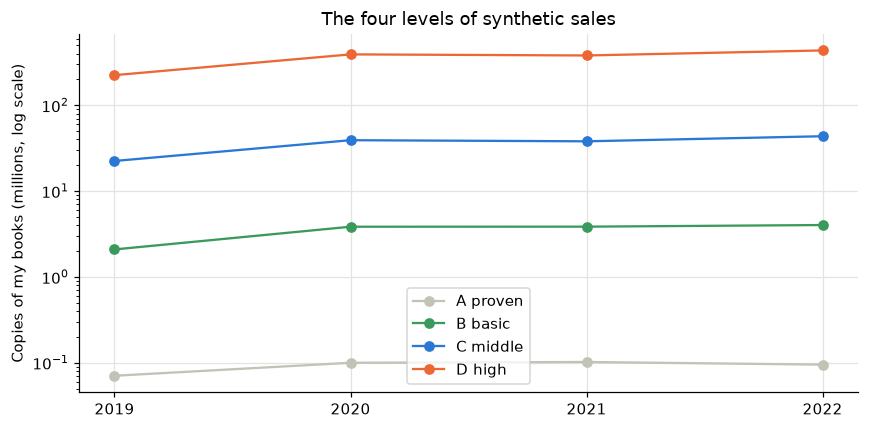

Spearman correlation with Amazon ratings: {'copies_A_proven': 0.53, 'copies_B_basic': 0.87, 'copies_C_middle': 0.88, 'copies_D_high': 0.88}
Implied US publisher e-book revenue from level C: 2.80 billion dollars (AAP 2024: 2.1)


,copies_A_proven,copies_B_basic,copies_C_middle,copies_D_high
year,,,,
2019,0.07,2.09,22.45,224.51
2020,0.10,3.85,39.20,392.01
2021,0.10,3.85,38.05,380.72
2022,0.10,4.02,43.59,435.83


In [7]:
totals = yearly.groupby("year")[LEVELS].sum() / 1e6
book_totals = yearly.groupby("parent_asin")[LEVELS].sum()
book_totals["rating_number"] = paid.set_index("parent_asin")["rating_number"]
spearman = book_totals[LEVELS].corrwith(book_totals["rating_number"], method="spearman")

y22 = yearly[yearly["year"] == 2022].merge(paid[["parent_asin", "price", "route"]], on="parent_asin")
publisher_value = (y22.loc[y22["route"] != "self-published", "copies_C_middle"] * y22.loc[y22["route"] != "self-published", "price"]).sum()
implied = publisher_value / share_2022 * 0.70

fig, ax = plt.subplots(figsize=(8, 4))
for column, color in zip(LEVELS, [GREY, GREEN, BLUE, ORANGE]):
    ax.plot(totals.index, totals[column], marker="o", color=color, label=column.replace("copies_", "").replace("_", " "))
ax.set_yscale("log")
ax.set_xticks(YEARS)
ax.set_ylabel("Copies of my books (millions, log scale)")
ax.set_title("The four levels of synthetic sales")
ax.legend()
plt.tight_layout()
plt.show()
print("Spearman correlation with Amazon ratings:", spearman.round(2).to_dict())
print(f"Implied US publisher e-book revenue from level C: {implied / 1e9:.2f} billion dollars (AAP 2024: {US_PUBLISHER_EBOOK_REVENUE / 1e9:.1f})")
totals.round(2)

- The order is right in every year: A < B < C < D.
- Levels B, C and D follow the ratings closely (Spearman **0.87–0.88**). Level A follows them less (**0.53**), because most books have only 0 or 1 verified review.
- Level C implies about **2.80 billion dollars** of US publisher e-book revenue, close to the AAP figure of **2.1 billion** for 2024. Level D would imply ten times more.

## 9. Decision

**Level C is used as the copies sold** in `04_eda_with_synthetic_sales.ipynb`.

- Levels A and B are real minimums, but far below any market figure.
- Level D is about ten times too high.
- Level C, with 5 buyers per rating, is a round number and matches both market checks in size.

The market figure of 487 million comes from a source without a stated year, so level C is a reasonable order of size, not a measurement. The analysis in `04`
treats these sales as an example of what a project with real sales data could do.

## 10. Export

I save the four levels for this notebook, and two simple tables for `04_eda_with_synthetic_sales.ipynb`: the books, and the **copies sold** of every book
in every year (level C).

In [8]:
sales = yearly[["parent_asin", "year", "reviews", "verified_reviews", "ratings"] + LEVELS].assign(is_synthetic=True)
sales.to_parquet(PROCESSED / "synthetic_sales_levels.parquet", index=False)
book_columns = ["parent_asin", "title", "author", "niche", "route", "price", "pages", "file_mb", "published", "publication_year",
                "self_published", "is_series", "author_earlier_books", "rating_number", "reviews_all", "verified_all", "verified_share"]
paid[book_columns].to_parquet(PROCESSED / "synthetic_books.parquet", index=False)
simple_sales = yearly[["parent_asin", "year", "copies_C_middle"]].rename(columns={"copies_C_middle": "copies_sold"})
simple_sales.to_parquet(PROCESSED / "kindle_sales_2019_2022.parquet", index=False)
paid[book_columns[:-3] + ["verified_share"]].to_parquet(PROCESSED / "kindle_books_sales.parquet", index=False)
print("Saved:", sales.shape, paid[book_columns].shape, simple_sales.shape)

Saved: (183720, 10) (70361, 17) (183720, 3)
